In [1]:
import sys
import os
import math

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [3]:
def train_joint_model(model, splits, N, B_ll, B_hl, hyperparams=None):
	is_hgm = model.get_type()

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# Hyperparamters ============
	if hyperparams is None:
		hyperparams = {
			'max_epochs': 5000,
			'min_epochs': 100,
			'max_patience': 20,
			'learning_rate': 1E-2,
			'reg_l1': 0.0,
			'reg_l2': 0.0,
			'loss_l1': 0.8,
			'loss_l2': 0.2,
			'dimensions': 1
		}

	max_epochs = hyperparams['max_epochs']
	min_epochs = hyperparams['min_epochs']
	max_patience = hyperparams['max_patience']

	optimizer = optax.adam(hyperparams['learning_rate'])

	reg_lambdas = hyperparams['reg_l1'], hyperparams['reg_l2']
	loss_lambdas = hyperparams['loss_l1'], hyperparams['loss_l2']

	n_dimensions = hyperparams['dimensions']
	# ===========================

	# training loop =======================================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mse_losses_per_split = list()
	mse_losses_tr_per_split = list()
	__grads_per_split = list()
	for train, test in splits:
		# splitting and initializing ========================== (this also moves the data to the GPU)
		N_train, N_test = jnp.array(N[train]), jnp.array(N[test])
		B_hl_train, B_hl_test = jnp.array(B_hl[train]), jnp.array(B_hl[test])
		B_ll_train, B_ll_test = jnp.array(B_ll[train]), jnp.array(B_ll[test])

		if is_hgm:
			params = model.init_params(seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions), (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, N_test, B_ll_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, N_train, B_ll_train).item()]
		else:
			losses = [model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas[0]).item()]
			losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas[0]).item()]
			mse_losses = [model.mse_loss_fn(params, N_test, B_ll_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, N_train, B_ll_train).item()]
		__grads = list()

		best_params = params
		best_loss = 1E3
		best_loss_tr = 1E3
		best_mse_loss = 1E3
		best_mse_loss_tr = 1E3

		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N, B_ll, B_hl, loss_lambdas, reg_lambdas)
				loss = model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas).item()
				loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, N_test, B_ll_test).item()
				mse_loss_tr = model.mse_loss_fn(params, N_train, B_ll_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N, B_ll, B_hl, loss_lambdas, reg_lambdas[0])
				loss = model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas[0]).item()
				loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas[0]).item()
				mse_loss = model.mse_loss_fn(params, N_test, B_ll_test).item()
				mse_loss_tr = model.mse_loss_fn(params, N_train, B_ll_train).item()

			__grads.append(__grad)

			# early stopping ================
			if epoch > min_epochs:
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mse_loss = mse_loss
					best_mse_loss_tr = mse_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mse_losses = mse_losses + [best_mse_loss for _ in range(max_epochs - epoch)]
						mse_losses_tr = mse_losses_tr + [best_mse_loss_tr for _ in range(max_epochs - epoch)]
						break

			losses.append(loss)
			losses_tr.append(loss_tr)
			mse_losses.append(mse_loss)
			mse_losses_tr.append(mse_loss_tr)
			# ===============================

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mse_losses_per_split.append(mse_losses)
		mse_losses_tr_per_split.append(mse_losses_tr)

		__grads_per_split.append(__grads)

		# predicting and scoring ========================================================================
		N_test_man = N_test @ params['U']
		N_test_rec = N_test_man @ jax.numpy.linalg.pinv(params['U'])
		N_test_res = N_test - N_test_rec
		if is_hgm:
			Y_pred = model.predict(B_ll_test, N_test_man, params['W1'], params['W2'])
		else:
			Y_pred = model.predict(B_ll_test, params['W'])

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(N_test_res.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mse_losses_per_split), np.array(mse_losses_tr_per_split), __grads_per_split

In [4]:
def train_joint_models(model, filenames, discrete_states, eigenworms, traces):
	selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mse_losses = list()
	models_mse_losses_tr = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mse_losses_per_split, mse_losses_tr_per_split,
		 __grads_per_split) = train_joint_model(model, splits,
												jnp.array(traces[i].values),
												jnp.array(eigenworms[i].values),
												jnp.array(discrete_states[i][selection].values))

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mse_losses.append(mse_losses_per_split)
		models_mse_losses_tr.append(mse_losses_tr_per_split)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mse_losses, models_mse_losses_tr, __models_grads

In [5]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & preprocess (GCamp & GFP)

In [6]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path)

path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# ARTIFICIAL DATA

In [7]:
filenames_art = list()
discrete_states_art = discrete_states_gfp.copy()
eigenworms_art = eigenworms_gfp.copy()
modes_manifold_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames_gfp)):
	art_filename, art_mode_manifold, art_trace_residual, art_trace, art_params = artificializer.artificialize(hgm, filenames_gfp[i], traces_gfp[i].columns, eigenworms_art[i], discrete_states_art[i])
	filenames_art.append(art_filename)
	modes_manifold_art.append(art_mode_manifold)
	traces_residual_art.append(art_trace_residual)
	traces_art.append(art_trace)

In [8]:
# train clm art

(clm_models_params_art,
 clm_models_scores_art,
 clm_models_losses_art, clm_models_losses_tr_art,
 clm_models_mse_losses_art, clm_models_mse_losses_tr_art,
 __clm_models_grads_art) = train_joint_models(clm,
											  filenames_art,
											  discrete_states_art,
											  eigenworms_art,
											  traces_art)

1/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  

In [9]:
# train hgm art

(hgm_models_params_art,
 hgm_models_scores_art,
 hgm_models_losses_art, hgm_models_losses_tr_art,
 hgm_models_mse_losses_art, hgm_models_mse_losses_tr_art,
 __hgm_models_grads_art) = train_joint_models(hgm,
											  filenames_art,
											  discrete_states_art,
											  eigenworms_art,
											  traces_art)

1/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  

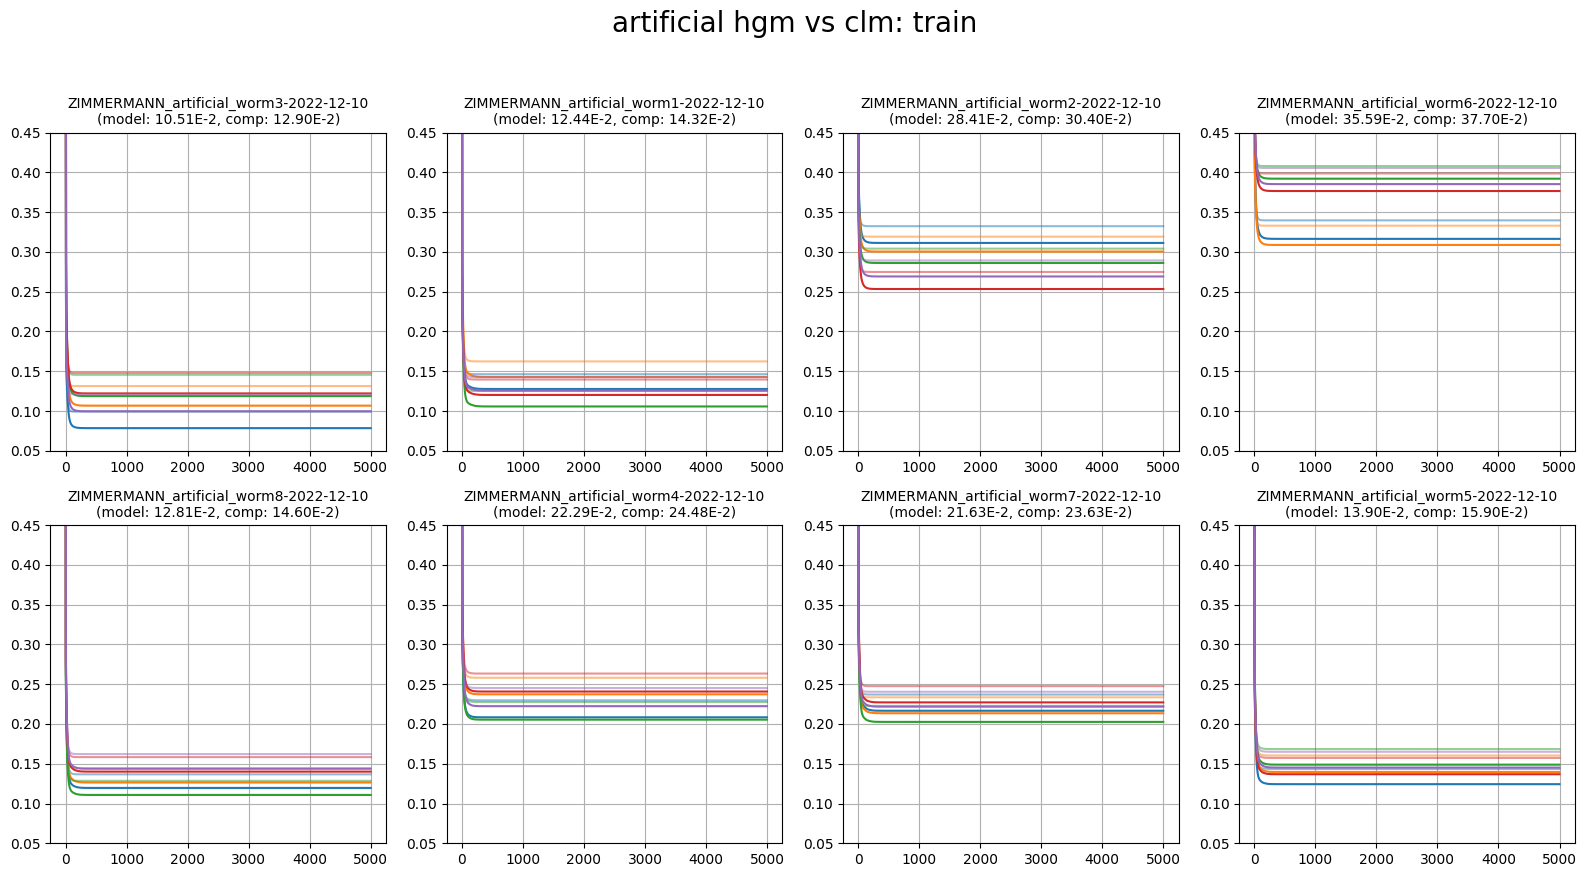

In [17]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_tr_art, clm_models_losses_tr_art, 'artificial hgm vs clm: train', None, (0.05, 0.45))

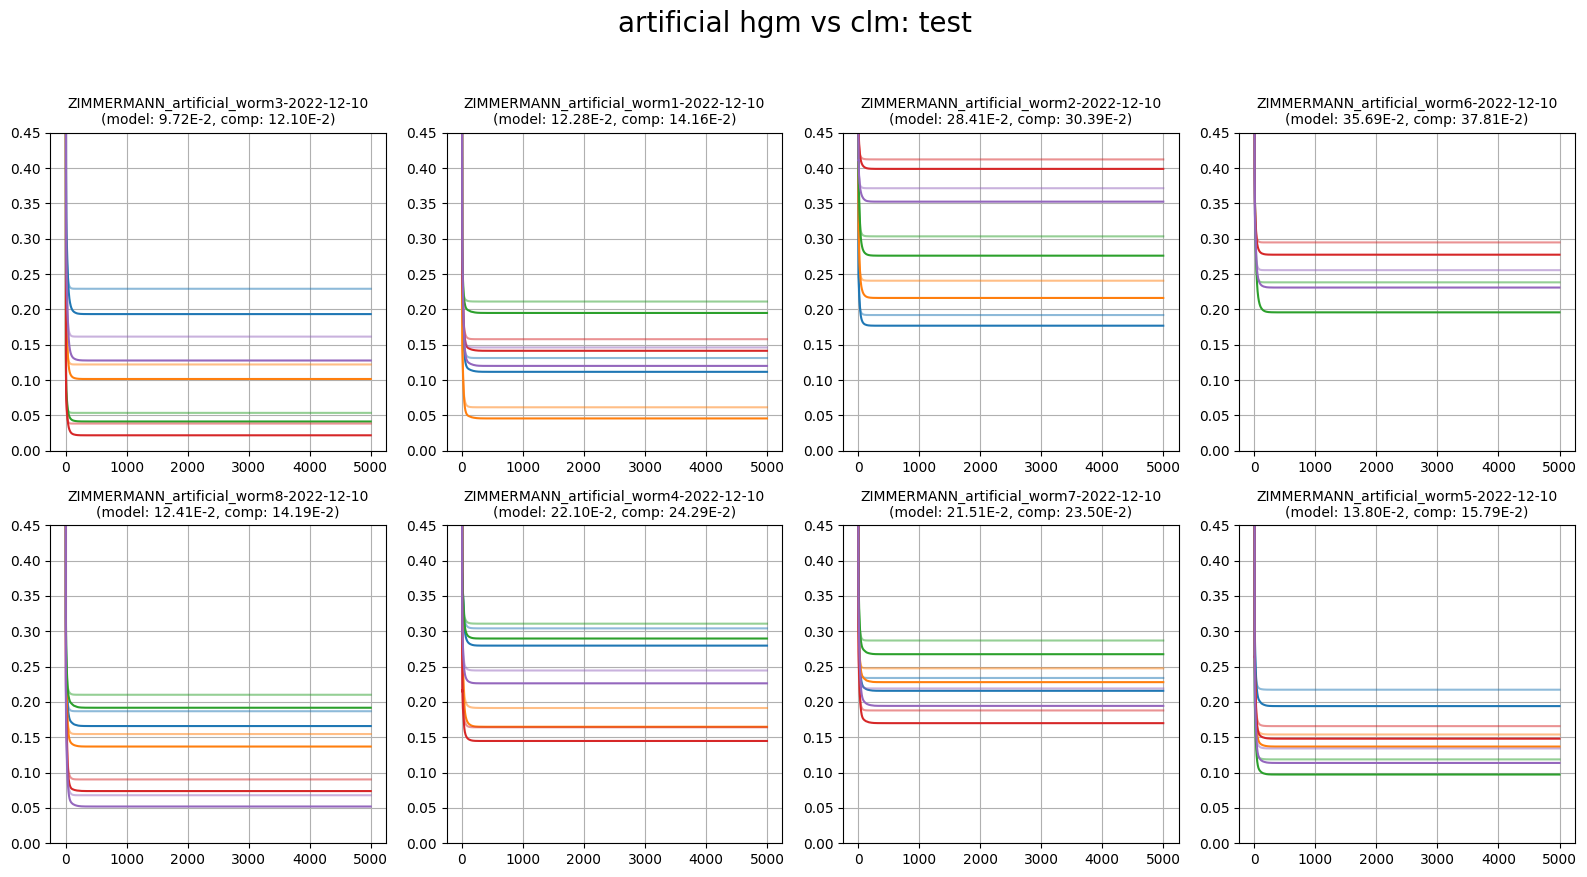

In [20]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_art, clm_models_losses_art, 'artificial hgm vs clm: test', None, (0.04, 0.45))

In [13]:
# assemble_art

neuron_scores_art = assemble(filenames_art, traces_art, clm_models_scores_art, hgm_models_scores_art)

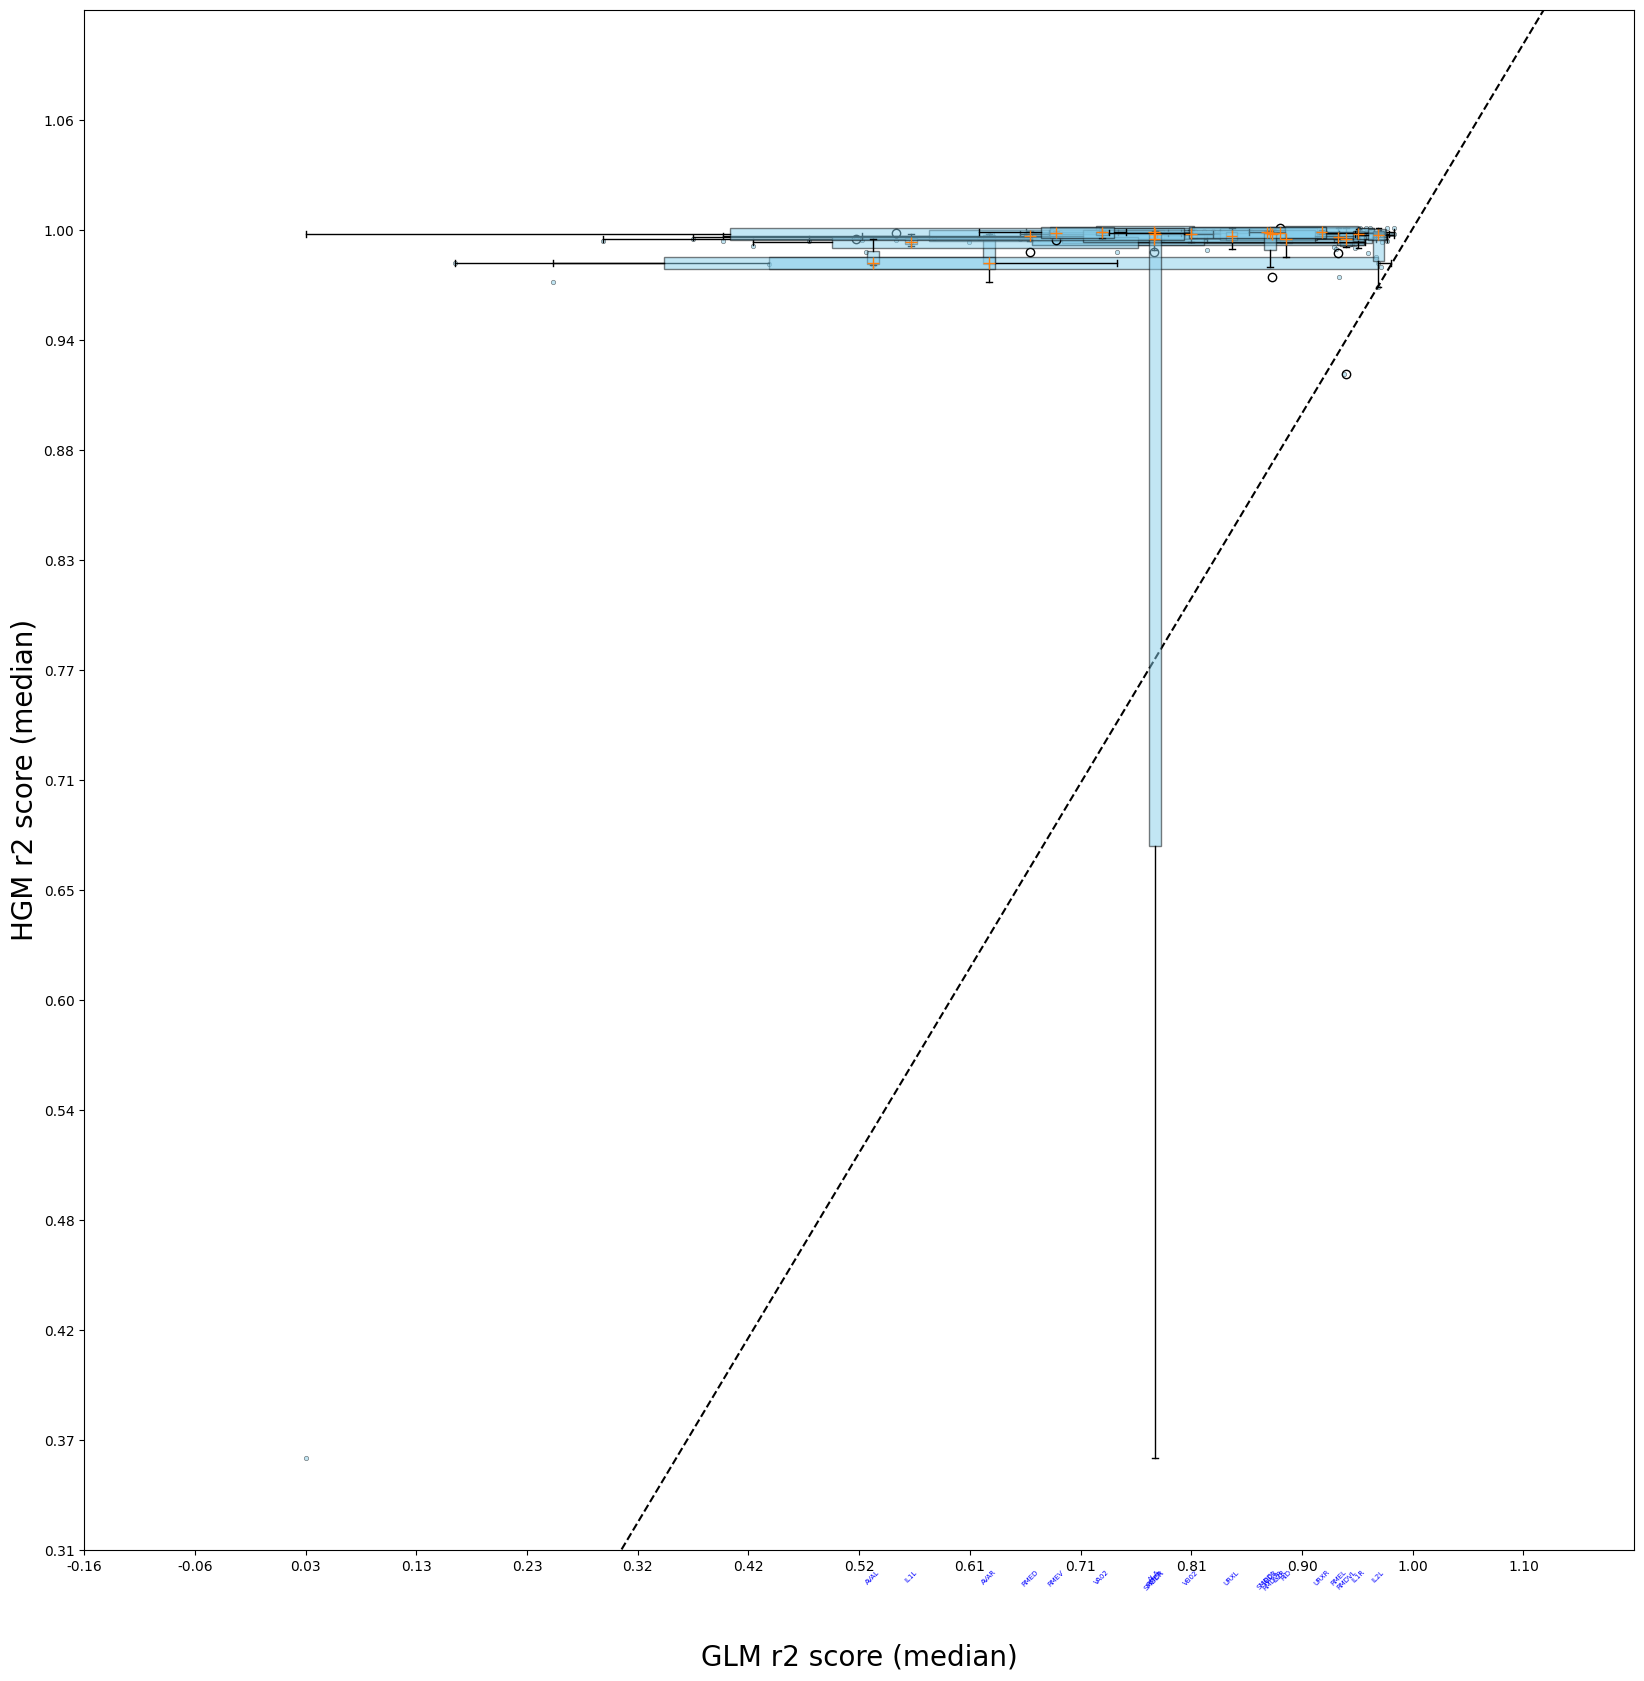

In [21]:
plot_utils.plot_performance_plot(neuron_scores_art, None, None, save=True)

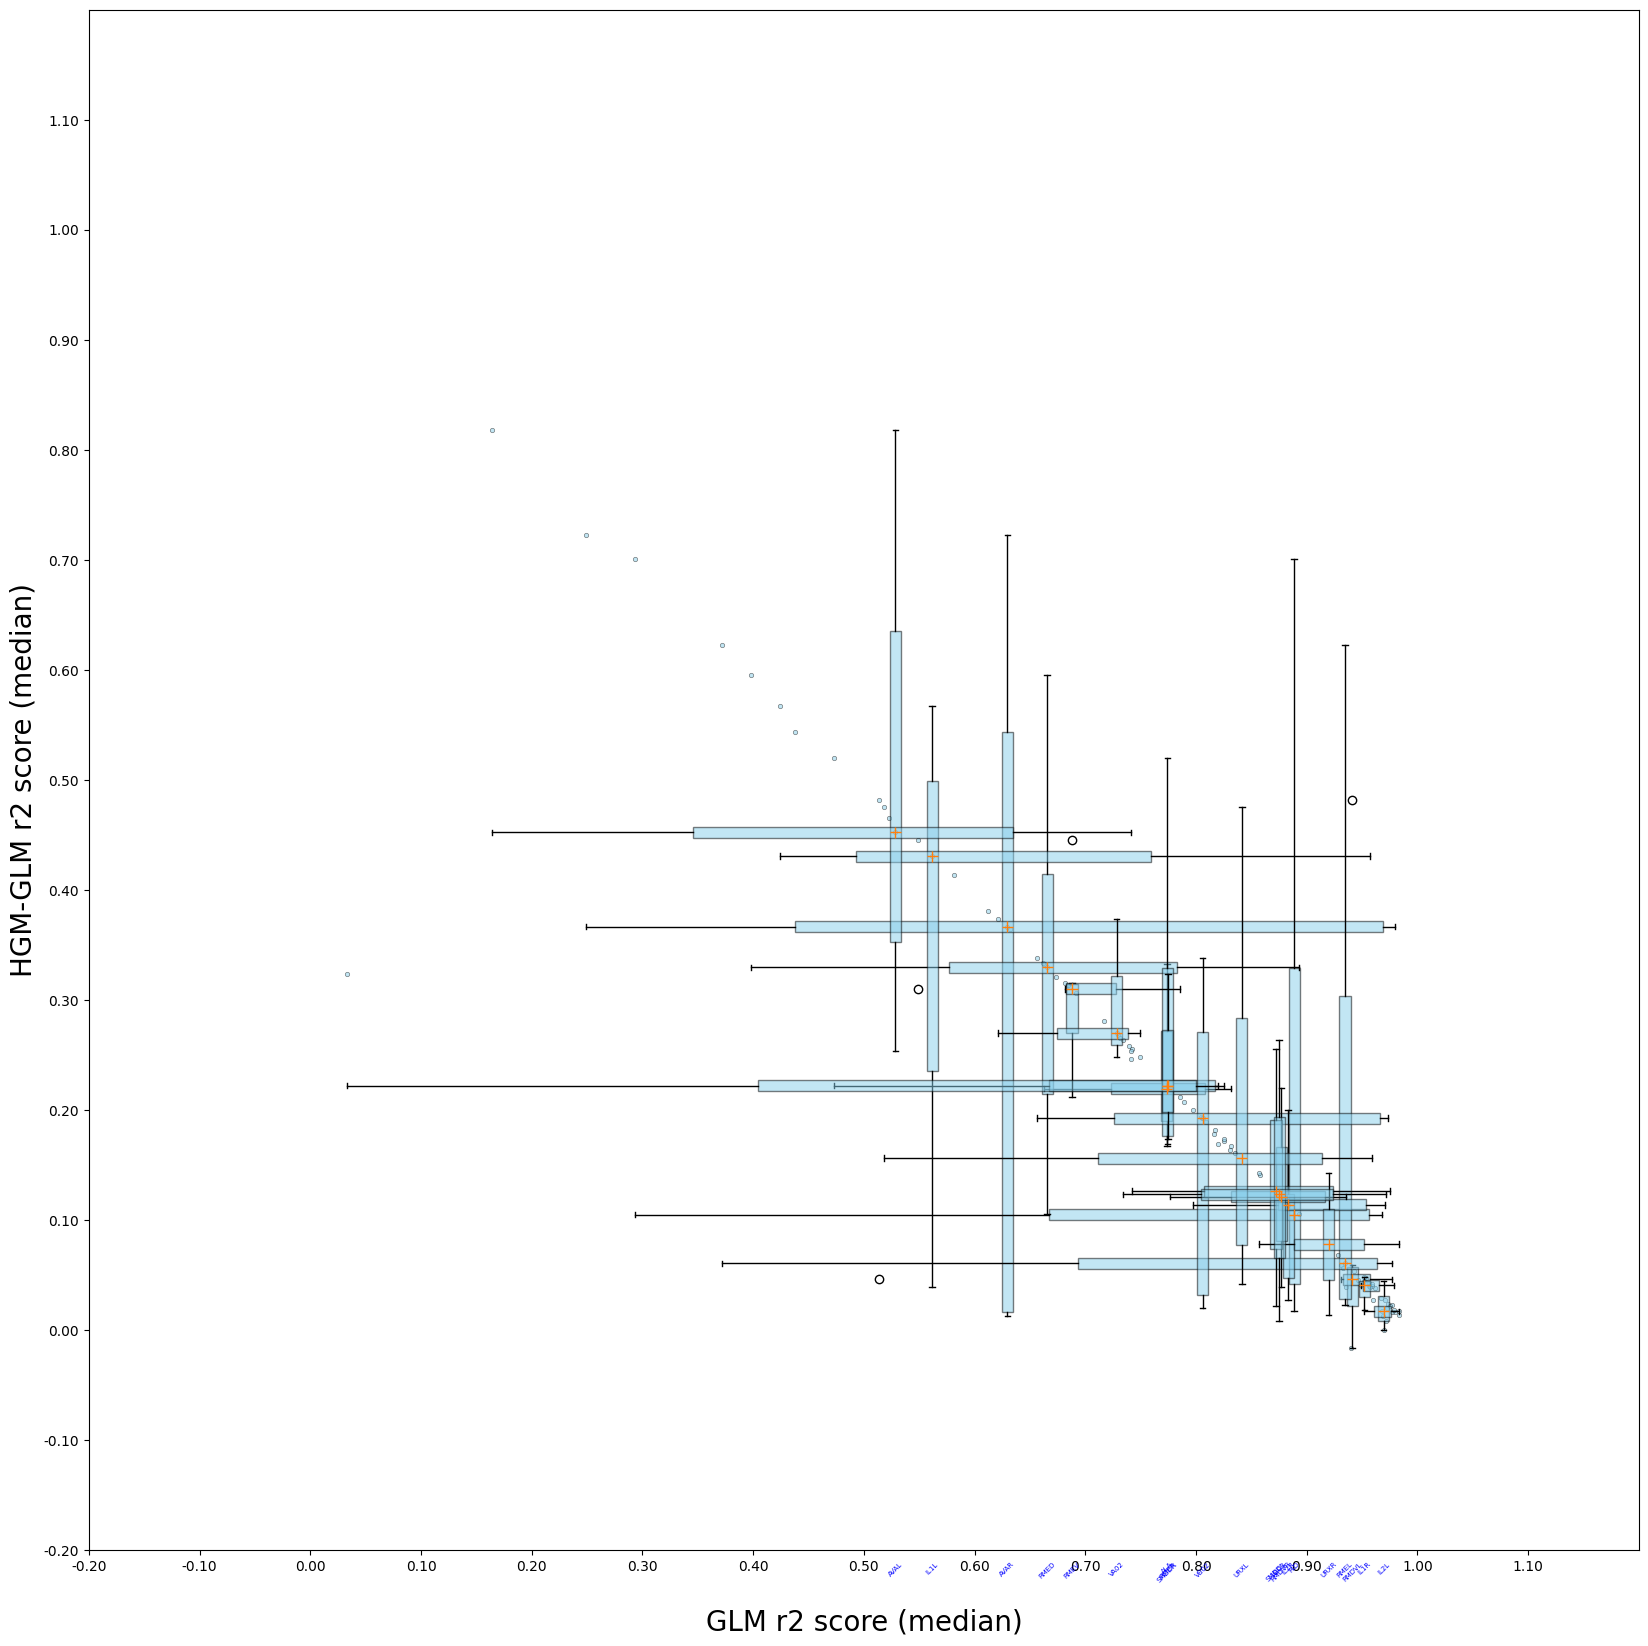

In [24]:
plot_utils.plot_improvement_plot(neuron_scores_art, None, (0, 1, 0, 1), save=True)

In [ ]:
# worm_id = 2
#
# hgm_predicted_traces = [[pd.DataFrame(data=hgm.predict(eigenworms_art[i].values, modes_manifold_art[i].values, params['W1'], params['W2']), columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
# plot_utils.plot_traces(traces_residual_art[worm_id], discrete_states_art[worm_id]['REV'], 'hgm predictions', hgm_predicted_traces[worm_id])
#
# clm_predicted_traces = [[pd.DataFrame(data=clm.predict(eigenworms_art[i].values, params['W']), columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
# plot_utils.plot_traces(traces_residual_art[worm_id], discrete_states_art[worm_id]['REV'], 'clm predictions', clm_predicted_traces[worm_id])

# ARTIFICIAL DATA END

In [ ]:
if False: raise Exception

# GCAMP

### CLM

In [ ]:
(clm_models_params_gcamp,
 clm_models_scores_gcamp,
 clm_models_losses_gcamp, clm_models_losses_tr_gcamp,
 clm_models_mse_losses_gcamp, clm_models_mse_losses_tr_gcamp,
 __clm_models_grads_gcamp) = train_joint_models(clm,
												filenames_gcamp,
												discrete_states_gcamp,
												eigenworms_gcamp,
												traces_gcamp)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  

### HGM

In [ ]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mse_losses_gcamp, hgm_models_mse_losses_tr,
 __hgm_models_grads_gcamp) = train_joint_models(hgm,
												filenames_gcamp,
												discrete_states_gcamp,
												eigenworms_gcamp,
												traces_gcamp)

In [ ]:
plot_utils.plot_losses(filenames_gcamp, hgm_models_losses_tr_gcamp, clm_models_losses_tr_gcamp, 'gcamp hgm vs clm: train', None, (0.0, 0.02))

In [ ]:
plot_utils.plot_losses(filenames_gcamp, hgm_models_losses_gcamp, clm_models_losses_gcamp, 'gcamp hgm vs clm: test', None, (0.0, 0.4))

### __loss gradient per weights over time

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax in axes:
    ax.set_ylim(-0.005, 0.004)

for i in range(1):
	gradsW = np.array([val['W'] for val in __clm_models_grads_gcamp[-1][i]])

	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads_gcamp[-1][i]])
	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads_gcamp[-1][i]])


	axes[0].plot(np.mean(gradsW1, axis=1))

	# axes[1].plot(np.mean(gradsW1, axis=1))
	axes[1].plot(np.mean(gradsW2, axis=1))

# GFP

### CLM

In [ ]:
(clm_models_params_gfp,
 clm_models_scores_gfp,
 clm_models_losses_gfp, clm_models_losses_tr_gfp,
 clm_models_mse_losses_gfp, clm_models_mse_losses_tr,
 __clm_models_grads_gfp) = train_joint_models(clm,
											  filenames_gfp,
											  discrete_states_gfp,
											  eigenworms_gfp,
											  traces_gfp)

### HGM

In [ ]:
(hgm_models_params_gfp,
 hgm_models_scores_gfp,
 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
 hgm_models_mse_losses_gfp, hgm_models_mse_losses_tr_gfp,
 __hgm_models_grads_gfp) = train_joint_models(hgm,
											  filenames_gfp,
											  discrete_states_gfp,
											  eigenworms_gfp,
											  traces_gfp)

In [ ]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, clm_models_losses_tr_gfp, 'gfp hgm vs clm: train', None,  None)

In [ ]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, clm_models_losses_gfp, 'gfp hgm vs clm: test', None,  None)

# assemble

In [ ]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, clm_models_scores_gcamp, hgm_models_scores_gcamp)
neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, clm_models_scores_gfp, hgm_models_scores_gfp)

# Plot

In [ ]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp, (-0.5, 0.3, -1.1, 0.4), save=True)

In [ ]:
plot_utils.plot_improvement_plot(neuron_scores_gcamp, neuron_scores_gfp, (-1, 0.5, -0.3, 1), save=True)